In [ ]:
%%capture
%pip install -U accelerate peft trl bitsandbytes transformers
%pip install evaluate sacrebleu rouge-score bert-score deepspeed

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Load Test Dataset/Corpus

In [ ]:
import pandas as pd
import numpy as np
import numpy as np
import evaluate
df = pd.read_json("/content/drive/MyDrive/MIT807/data/silver/question_answers/test.json")
# df['answer'] = df['answer'].str.strip().str.lower()
df.info()
df.head(1)

<class 'pandas.core.frame.DataFrame'>
Index: 1973 entries, 0 to 1972
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   instruction      1973 non-null   object
 1   question         1973 non-null   object
 2   answer           1973 non-null   object
 3   source           1973 non-null   object
 4   context          1973 non-null   object
 5   complex_cot      128 non-null    object
 6   category         1973 non-null   object
 7   token_question   1973 non-null   object
 8   token_answer     1973 non-null   object
 9   kind             595 non-null    object
 10  options          1477 non-null   object
 11  long_answer      1126 non-null   object
 12  extract          198 non-null    object
 13  type             1973 non-null   object
 14  Product Name     66 non-null     object
 15  Status           3 non-null      object
 16  question_length  1973 non-null   int64 
 17  answer_length    1973 non-null   int64

,instruction,question,answer,source,context,complex_cot,category,token_question,token_answer,kind,options,long_answer,extract,type,Product Name,Status,question_length,answer_length
0,You are a medical expert with advanced knowled...,Do severe but preventable foot burn injury in ...,A:yes,pubmedpqaa,['Due to the sensory loss in the lower extremi...,None,diabetes,do severe but preventable foot burn injury in ...,yes,None,"{'A': 'yes', 'B': 'no', 'C': 'maybe'}",Severe clinical consequences of foot burn inju...,None,MCQ,None,None,13,1


In [ ]:
person_df = pd.read_csv("/content/drive/MyDrive/MIT807/data/silver/question_answers/person_eval.csv")
# df['answer'] = df['answer'].str.strip().str.lower()
person_df.info()
person_df.head(1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   10 non-null     int64  
 1   instruction  10 non-null     object 
 2   question     10 non-null     object 
 3   answer       10 non-null     object 
 4   context      6 non-null      object 
 5   complex_cot  0 non-null      float64
 6   options      0 non-null      float64
 7   long_answer  0 non-null      float64
 8   source       10 non-null     object 
 9   category     10 non-null     object 
 10  type         10 non-null     object 
dtypes: float64(3), int64(1), object(7)
memory usage: 1012.0+ bytes


,Unnamed: 0,instruction,question,answer,context,complex_cot,options,long_answer,source,category,type
0,1346,You are a medical expert with advanced knowled...,What is METPLITIN CO used for?,METPLITIN CO combines sitagliptin and metformi...,A patient with type 2 diabetes asks about what...,NaN,NaN,NaN,patient information leaflet,medication,QA


In [ ]:
diabetica_df = pd.read_csv("/content/drive/MyDrive/MIT807/data/silver/question_answers/output_new/diabetica_response_test.csv", names=['input','output'])
diabetica_df['diabetica_output'] = diabetica_df.apply(lambda row:
                                              row['output'].replace(row['input'], ''), axis=1)\
                                              .str.replace("<|im_end|>", "").str.replace("<|endoftext|>", "")\
                                              .str.replace("<|im_start|>", "").str.replace("response\n", "")\
                                              .str.replace("[OptionLetter]:", "").str.replace("[OptionText]", "").str.strip()\
                                              .str.replace(r'[\[\]]', '', regex=True)
                                              # .str.strip().str.lower()
diabetica_df.drop(columns = "output", inplace=True)
diabetica_df['question'] = diabetica_df['input'].str.split('# Question\n', expand=True, n=1)[1].str.split('\n', expand=True)[0].str.strip()
diabetica_df.drop_duplicates(inplace=True, subset='input')
diabetica_df.info()
diabetica_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1973 entries, 0 to 1972
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   input             1973 non-null   object
 1   diabetica_output  1973 non-null   object
 2   question          1973 non-null   object
dtypes: object(3)
memory usage: 46.4+ KB


,input,diabetica_output,question
0,"\nYou are a helpful, respectful, honest, and s...",A yes\n\nDiabetic patients often suffer from p...,Do severe but preventable foot burn injury in ...
1,"\nYou are a helpful, respectful, honest, and s...",B: No\n\nThe data presented indicates that fol...,Do after 6years of intraperitoneal insulin adm...
2,"\nYou are a helpful, respectful, honest, and s...",Changing your diabetes medications should alwa...,Should I change my diabetes medication on my own?
3,"\nYou are a helpful, respectful, honest, and s...",D: 3-hydroxyacyl-CoA dehydrogenase\n\nThe medi...,A 45 year old female patient comes to the clin...
4,"\nYou are a helpful, respectful, honest, and s...",doc,What is lactic acidosis and why is it importan...


In [ ]:
qwen_base_df = pd.read_csv("/content/drive/MyDrive/MIT807/data/silver/question_answers/output_new/base_qwen_response_test.csv", names=['input','output'])
qwen_base_df['qwen_base_output'] = qwen_base_df.apply(lambda row:
                                              row['output'].replace(row['input'], ''), axis=1)\
                                              .str.replace("<|im_end|>", "").str.replace("<|endoftext|>", "")\
                                              .str.replace("[OptionLetter]:", "").str.replace("[OptionText]", "").str.strip()\
                                              .str.replace(r'[\[\]]', '', regex=True)
                                              # .str.strip().str.lower()
qwen_base_df.drop(columns = "output", inplace=True)
qwen_base_df['question'] = qwen_base_df['input'].str.split('# Question\n', expand=True, n=1)[1].str.split('\n', expand=True)[0].str.strip()
qwen_base_df.drop_duplicates(inplace=True, subset='input')
qwen_base_df.info()
qwen_base_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 3946 entries, 0 to 3946
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   input             3946 non-null   object
 1   qwen_base_output  3946 non-null   object
 2   question          3946 non-null   object
dtypes: object(3)
memory usage: 123.3+ KB


,input,qwen_base_output,question
0,"\nYou are a helpful, respectful, honest, and s...",A: yes\n\nDiabetic patients with peripheral ne...,Do severe but preventable foot burn injury in ...
1,"\nYou are a helpful, respectful, honest, and s...",A\n: yes\n\nExplanation: According to the stud...,Do after 6years of intraperitoneal insulin adm...
2,"\nYou are a helpful, respectful, honest, and s...","No, you should **not** change your diabetes me...",Should I change my diabetes medication on my own?
3,"\nYou are a helpful, respectful, honest, and s...",C\nCPT-I stands for Carnitine Palmitoyltransfe...,A 45 year old female patient comes to the clin...
4,"\nYou are a helpful, respectful, honest, and s...",Lactic acidosis is a metabolic complication ch...,What is lactic acidosis and why is it importan...


In [ ]:
qwen_df = pd.read_csv("/content/drive/MyDrive/MIT807/data/silver/question_answers/output_new/qwen_qlora_fine_tuned_response_test_v2.csv", names=['input','output'])
qwen_df['qwen_qlora_output'] = qwen_df.apply(lambda row:
                                              row['output'].replace(row['input'], ''), axis=1)\
                                              .str.replace("<|im_end|>", "").str.replace("<|endoftext|>", "")\
                                              .str.replace("[OptionLetter]:", "").str.replace("[OptionText]", "").str.strip()\
                                              .str.replace(r'[\[\]]', '', regex=True)
                                              # .str.strip().str.lower()
qwen_df.drop(columns = "output", inplace=True)
qwen_df.drop_duplicates(inplace=True, subset='input')
qwen_df = qwen_df.rename(columns={"output": "qwen_qlora_output"})
qwen_df.info()
qwen_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1973 entries, 0 to 1972
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   input              1973 non-null   object
 1   qwen_qlora_output  1973 non-null   object
dtypes: object(2)
memory usage: 31.0+ KB


,input,qwen_qlora_output
0,"\nYou are a helpful, respectful, honest, and s...",A: yes\n\nDiabetic patients with peripheral ne...
1,"\nYou are a helpful, respectful, honest, and s...",A\n: yes\n\nExplanation: According to the stud...
2,"\nYou are a helpful, respectful, honest, and s...","No, you should **not** change your diabetes me..."
3,"\nYou are a helpful, respectful, honest, and s...",C\nCPT-I stands for Carnitine Palmitoyltransfe...
4,"\nYou are a helpful, respectful, honest, and s...",Lactic acidosis is a metabolic complication ch...


In [ ]:
biomistral_df = pd.read_csv("/content/drive/MyDrive/MIT807/data/silver/question_answers/output_new/biomistral_qlora_response_test.csv", names=['input','output'])
biomistral_df['biomistral_qlora_output'] = biomistral_df.apply(lambda row:
                                                row['output'].replace(row['input'], ''), axis=1)\
                                                .str.replace("<s>", "").str.replace("</s>", "")\
                                                .str.replace("[OptionLetter]:", "").str.replace("[OptionText]", "").str.strip()\
                                                .str.replace(r'[\[\]]', '', regex=True).str.replace('Answer:', "")
#                                               # .str.strip().str.lower()
biomistral_df['question'] = biomistral_df['input'].str.split('# Question\n', expand=True, n=1)[1].str.split('\n', expand=True)[0].str.strip()
biomistral_df.drop(columns = "output", inplace=True)
biomistral_df.drop_duplicates(inplace=True, subset='input')
biomistral_df.info()
biomistral_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 1973 entries, 0 to 1973
Data columns (total 3 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   input                    1973 non-null   object
 1   biomistral_qlora_output  1973 non-null   object
 2   question                 1973 non-null   object
dtypes: object(3)
memory usage: 61.7+ KB


,input,biomistral_qlora_output,question
0,"\nYou are a helpful, respectful, honest, and s...",Diabetes Virtual Doctor: The answer is A: yes....,Do severe but preventable foot burn injury in ...
1,"\nYou are a helpful, respectful, honest, and s...",A: yes : Intraperitoneal insulin administrati...,Do after 6years of intraperitoneal insulin adm...
2,"\nYou are a helpful, respectful, honest, and s...",Hello! It's important to remember that your he...,Should I change my diabetes medication on my own?
3,"\nYou are a helpful, respectful, honest, and s...",You have been asked about the mechanism of act...,A 45 year old female patient comes to the clin...
4,"\nYou are a helpful, respectful, honest, and s...",Lactic acidosis is a condition where there is...,What is lactic acidosis and why is it importan...


In [ ]:
biomistral_base_df = pd.read_csv("/content/drive/MyDrive/MIT807/data/silver/question_answers/output_new/base_biomistral_response_test.csv", names=['input','output'])
biomistral_base_df['biomistral_base_output'] = biomistral_base_df.apply(lambda row:
                                                row['output'].replace(row['input'], ''), axis=1)\
                                                .str.replace("<s>", "").str.replace("</s>", "")\
                                                .str.replace("[OptionLetter]:", "").str.replace("[OptionText]", "").str.strip()\
                                                .str.replace(r'[\[\]]', '', regex=True)
#                                               # .str.strip().str.lower()
biomistral_base_df['question'] = biomistral_base_df['input'].str.split('# Question\n', expand=True, n=1)[1].str.split('\n', expand=True)[0].str.strip()
biomistral_base_df.drop(columns = "output", inplace=True)
biomistral_base_df.drop_duplicates(inplace=True, subset='input')
biomistral_base_df.info()
biomistral_base_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1973 entries, 0 to 1972
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   input                   1973 non-null   object
 1   biomistral_base_output  1973 non-null   object
 2   question                1973 non-null   object
dtypes: object(3)
memory usage: 46.4+ KB


,input,biomistral_base_output,question
0,"\nYou are a helpful, respectful, honest, and s...",A: no. The development of ulcers on the feet c...,Do severe but preventable foot burn injury in ...
1,"\nYou are a helpful, respectful, honest, and s...","B: No, because there is no significant change ...",Do after 6years of intraperitoneal insulin adm...
2,"\nYou are a helpful, respectful, honest, and s...",Diabetes mellitus is a chronic disease charact...,Should I change my diabetes medication on my own?
3,"\nYou are a helpful, respectful, honest, and s...",A: This drug works by inhibition of HMG CoA re...,A 45 year old female patient comes to the clin...
4,"\nYou are a helpful, respectful, honest, and s...",Lactic acidosis is a condition where there is ...,What is lactic acidosis and why is it importan...


In [ ]:
biomedlm_base_df = pd.read_csv("/content/drive/MyDrive/MIT807/data/silver/question_answers/output_new/base_biomedlm_response_test.csv")
biomedlm_base_df['biomedlm_base_output'] = biomedlm_base_df['output'].str.split("\nA:\n", expand=True)[1].str.strip()
biomedlm_base_df.drop(columns = "output", inplace=True)
biomedlm_base_df.drop_duplicates(inplace=True, subset='input')
biomedlm_base_df['question'] = biomedlm_base_df['input'].str.split('\n\nQ: ', expand=True, n=1)[1].str.split('\n', expand=True)[0].str.strip()
biomedlm_base_df.info()
biomedlm_base_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1973 entries, 0 to 1972
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   input                 1973 non-null   object
 1   biomedlm_base_output  1970 non-null   object
 2   question              1973 non-null   object
dtypes: object(3)
memory usage: 46.4+ KB


,input,biomedlm_base_output,question
0,"\nYou are a helpful, respectful, honest, and s...","� boiling water baths and socks, especially th...",Do severe but preventable foot burn injury in ...
1,"\nYou are a helpful, respectful, honest, and s...","�boiled boiled, but the {D': '{[{[}, IAA}]/'.....",Do after 6years of intraperitoneal insulin adm...
2,"\nYou are a helpful, respectful, honest, and s...",�\n================================== boiling ...,Should I change my diabetes medication on my own?
3,"\nYou are a helpful, respectful, honest, and s...",�meals were you paired with 'insulin sensitise...,A 45 year old female patient comes to the clin...
4,"\nYou are a helpful, respectful, honest, and s...","�\n==""} or a lactate level? boiled egg? {#Sec7...",What is lactic acidosis and why is it importan...


In [ ]:
biomedlm_df = pd.read_csv("/content/drive/MyDrive/MIT807/data/silver/question_answers/output_new/biomedlm_qlora_response_test.csv")
biomedlm_df['biomedlm_qlora_output'] = biomedlm_df['output'].str.split("## Response\n...", expand=True)[1].str.strip()
biomedlm_df.drop(columns = "output", inplace=True)
biomedlm_df.drop_duplicates(inplace=True, subset='input')
biomedlm_df['question'] = biomedlm_df['input'].str.split('\n## Question\n', expand=True, n=1)[1].str.split('\n', expand=True)[0].str.strip()
biomedlm_df.info()
biomedlm_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1973 entries, 0 to 1972
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   input                  1973 non-null   object
 1   biomedlm_qlora_output  1972 non-null   object
 2   question               1973 non-null   object
dtypes: object(3)
memory usage: 46.4+ KB


,input,biomedlm_qlora_output,question
0,"\nYou are a helpful, respectful, honest, and s...",�If you don’t know?': \nExplanatory foot ulcer...,Do severe but preventable foot burn injury in ...
1,"\nYou are a helpful, respectful, honest, and s...",�istan: 'low-Normal Concentration of glucose l...,Do after 6years of intraperitoneal insulin adm...
2,"\nYou are a helpful, respectful, honest, and s...",� ø Remind patients to avoid false positives o...,Should I change my diabetes medication on my own?
3,"\nYou are a helpful, respectful, honest, and s...",�) Payne *et al*.\nThe purpose of this study':...,A 45 year old female patient comes to the clin...
4,"\nYou are a helpful, respectful, honest, and s...","� Educating physicians, nurses, and caregivers...",What is lactic acidosis and why is it importan...


In [ ]:
final_df = qwen_base_df.merge(qwen_df, on='input')
final_df = df.merge(final_df, on='question')
final_df = final_df.merge(biomistral_base_df[['biomistral_base_output', 'question']], on='question')
final_df = final_df.merge(biomistral_df[['biomistral_qlora_output', 'question']], on='question')
final_df = final_df.merge(biomedlm_base_df[['biomedlm_base_output', 'question']], on='question')
final_df = final_df.merge(biomedlm_df[['biomedlm_qlora_output', 'question']], on='question')
final_df = final_df.merge(diabetica_df, on='question')
final_df = final_df.drop(columns=['token_question', 'token_answer','complex_cot', 'Product Name', 'question_length', 'answer_length'])
final_df = final_df.drop_duplicates(subset='question')
final_df['biomistral_base_answer'] = final_df['biomistral_base_output'][final_df['type']!='QA']\
                                            .str.split('\n\n', n=1, expand=True)[0].str.strip()\
                                            .str.split(',', n=1, expand=True)[0]\
                                            .str.split('.',n=1, expand=True)[0].str.strip()
final_df['biomistral_qlora_answer'] = final_df['biomistral_qlora_output'][final_df['type']!='QA']\
                                            .str.split('\n\n', n=1, expand=True)[0].str.replace("Diabetes Virtual Doctor:",'').str.replace("The answer is",'')\
                                            .str.split(',', n=1, expand=True)[0]\
                                            .str.split('.',n=1, expand=True)[0].str.strip()
final_df['qwen_base_answer'] = final_df['qwen_base_output'] [final_df['type']!='QA']\
                                        .str.split('\n\n', n=1, expand=True)[0]\
                                        .str.replace("\n",":").str.replace("::", ":")\
                                        .str.split(',', n=1, expand=True)[0]\
                                        .str.split('.',n=1, expand=True)[0].str.strip()
final_df['qwen_qlora_answer'] = final_df['qwen_qlora_output'] [final_df['type']!='QA']\
                                        .str.split('\n\n', n=1, expand=True)[0]\
                                        .str.replace("\n",":").str.replace("::", ":")\
                                        .str.split(',', n=1, expand=True)[0]\
                                        .str.split('.',n=1, expand=True)[0].str.strip()
final_df['diabetica_answer'] = final_df['diabetica_output'] [final_df['type']!='QA']\
                                        .str.split('\n\n', n=1, expand=True)[0]\
                                        .str.split(',', n=1, expand=True)[0]\
                                        .str.split('.',n=1, expand=True)[0].str.strip()
final_df.info()
final_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 1865 entries, 0 to 2179
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   instruction              1865 non-null   object
 1   question                 1865 non-null   object
 2   answer                   1865 non-null   object
 3   source                   1865 non-null   object
 4   context                  1865 non-null   object
 5   category                 1865 non-null   object
 6   kind                     520 non-null    object
 7   options                  1402 non-null   object
 8   long_answer              1125 non-null   object
 9   extract                  198 non-null    object
 10  type                     1865 non-null   object
 11  Status                   3 non-null      object
 12  input_x                  1865 non-null   object
 13  qwen_base_output         1865 non-null   object
 14  qwen_qlora_output        1865 non-null   obje

,instruction,question,answer,source,context,category,kind,options,long_answer,extract,...,biomistral_qlora_output,biomedlm_base_output,biomedlm_qlora_output,input_y,diabetica_output,biomistral_base_answer,biomistral_qlora_answer,qwen_base_answer,qwen_qlora_answer,diabetica_answer
0,You are a medical expert with advanced knowled...,Do severe but preventable foot burn injury in ...,A:yes,pubmedpqaa,['Due to the sensory loss in the lower extremi...,diabetes,None,"{'A': 'yes', 'B': 'no', 'C': 'maybe'}",Severe clinical consequences of foot burn inju...,None,...,Diabetes Virtual Doctor: The answer is A: yes....,"� boiling water baths and socks, especially th...",�If you don’t know?': \nExplanatory foot ulcer...,"\nYou are a helpful, respectful, honest, and s...",A yes\n\nDiabetic patients often suffer from p...,A: no,A: yes,A: yes,A: yes,A yes
1,You are a medical expert with advanced knowled...,Do after 6years of intraperitoneal insulin adm...,A:yes,pubmedpqaa,['Low concentrations of insulin-like growth fa...,medication,None,"{'A': 'yes', 'B': 'no', 'C': 'maybe'}","After 6 years of treatment with CIPII, IGF-I c...",None,...,A: yes : Intraperitoneal insulin administrati...,"�boiled boiled, but the {D': '{[{[}, IAA}]/'.....",�istan: 'low-Normal Concentration of glucose l...,"\nYou are a helpful, respectful, honest, and s...",B: No\n\nThe data presented indicates that fol...,B: No,A: yes : Intraperitoneal insulin administratio...,A: yes,A: yes,B: No
2,You are a medical expert with advanced knowled...,Should I change my diabetes medication on my own?,Dont make any changes to your medication witho...,Consumer queries,Discussing medication needs with a healthcare ...,diabetes,None,None,None,Dont make any changes to your medication witho...,...,Hello! It's important to remember that your he...,�\n================================== boiling ...,� ø Remind patients to avoid false positives o...,"\nYou are a helpful, respectful, honest, and s...",Changing your diabetes medications should alwa...,NaN,NaN,NaN,NaN,NaN
3,You are a medical expert with advanced knowled...,A 45 year old female patient comes to the clin...,C:CPT-I,mcqa,nan,diabetes,train,"{'A': '3-KetoacylCoA thiolase', 'B': 'HMG-CoA ...",The sulfonylurea drugs (glyburide and tolbuta...,None,...,You have been asked about the mechanism of act...,�meals were you paired with 'insulin sensitise...,�) Payne *et al*.\nThe purpose of this study':...,"\nYou are a helpful, respectful, honest, and s...",D: 3-hydroxyacyl-CoA dehydrogenase\n\nThe medi...,A: This drug works by inhibition of HMG CoA re...,You have been asked about the mechanism of act...,C:CPT-I stands for Carnitine Palmitoyltransfer...,C:CPT-I stands for Carnitine Palmitoyltransfer...,D: 3-hydroxyacyl-CoA dehydrogenase
4,You are a medical expert with advanced knowled...,What is lactic acidosis and why is it importan...,Lactic acidosis is a buildup of lactic acid in...,patient information leaflet,A patient asks about a rare but serious risk a...,medication,None,None,None,None,...,Lactic acidosis is a condition where there is...,"�\n==""} or a lactate level? boiled egg? {#Sec7...","� Educating physicians, nurses, and caregivers...","\nYou are a helpful, respectful, honest, and s...",doc,NaN,NaN,NaN,NaN,NaN


In [ ]:
final_df['source'].value_counts()

,count
source,
pubmedpqaa,890
mcqa,245
medqa,197
Consumer queries,161
medical-o1-reasoning-SFT,96
healthcare_facts,93
mmlu,69
patient information leaflet,43
professional information,23


# Evaluate Performance

In [ ]:
import nltk
nltk.download('wordnet')
nltk.download('punkt_tab')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
from nltk.translate.meteor_score import meteor_score
from nltk.translate.bleu_score import sentence_bleu
from sacrebleu import corpus_bleu
from nltk.tokenize import word_tokenize
from nltk.translate.meteor_score import single_meteor_score
from nltk.corpus import wordnet

In [ ]:
import evaluate
# Assuming df['predicted'] and df['actual'] are lists of labels (e.g., integers or strings)

# Load metrics (only once)
precision_metric = evaluate.load("precision")
recall_metric = evaluate.load("recall")
f1_metric = evaluate.load("f1")
accuracy_metric = evaluate.load("accuracy")

def compute_mcq_metrics(predicted, actual):
    # Map answer letters to numerical labels
    label_map = {label: i for i, label in enumerate(sorted(list(set(actual + predicted))))}
    predicted_numeric = [label_map[label] for label in predicted]
    actual_numeric = [label_map[label] for label in actual]

    # Call .compute() and capture the results (which are dictionaries)
    accuracy_result = accuracy_metric.compute(predictions=predicted_numeric, references=actual_numeric)

    return {
        # Extract the score from the result dictionary
        "accuracy": accuracy_result['accuracy'],
    }

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [ ]:
import evaluate
import numpy as np
# from nltk.translate.bleu_score import sentence_bleu # Not needed if using evaluate.load("bleu")

# Load metrics (only once)
bleu_metric = evaluate.load("bleu")
rouge_metric = evaluate.load("rouge")
bert_metric = evaluate.load("bertscore")

def compute_metrics(predicted, actual):
    # Assuming 'predicted' and 'actual' are lists of strings (raw text)

    # 1. BLEU Score (using the loaded evaluate metric)
    bleu_results = bleu_metric.compute(
        predictions=predicted,
        references=actual
        # weights argument is not standard for the evaluate bleu metric
    )
    bleu = bleu_results["bleu"]

    # 2. ROUGE Score
    rouge = rouge_metric.compute(
        predictions=predicted,
        references=actual,
        use_aggregator=True,
        use_stemmer=True
    )

    # 3. BERTScore
    bert = bert_metric.compute(
        predictions=predicted,
        references=actual,
        lang="en"#"en-sci"
    )
    # The returned f1 is a list of scores, typically use the mean/median/max
    # bert_f1 = float(np.median(bert["f1"]))

    return {
        # "BLEU": bleu,
        # # Extract the fmeasure from the nested dictionary
        # "Rouge1": rouge["rouge1"],
        # "RougeL": rouge["rougeL"],
        "BERTScore-F1": float(np.median(bert["f1"]))
    }

In [ ]:
final_df.columns

Index(['instruction', 'question', 'answer', 'source', 'context', 'category',
       'kind', 'options', 'long_answer', 'extract', 'type', 'Status',
       'input_x', 'qwen_base_output', 'qwen_qlora_output',
       'biomistral_base_output', 'biomistral_qlora_output',
       'biomedlm_base_output', 'biomedlm_qlora_output', 'input_y',
       'diabetica_output', 'biomistral_base_answer', 'biomistral_qlora_answer',
       'qwen_base_answer', 'qwen_qlora_answer', 'diabetica_answer'],
      dtype='object')

In [ ]:
measure_df = final_df[(final_df['type'] =='QA')]
diabetica_results = compute_metrics(measure_df['diabetica_output'].tolist(),
                                    measure_df['answer'].tolist())
# diabetica_results

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
measure_df = final_df[final_df['type'] =='QA']
qwen_base_results = compute_metrics(measure_df['qwen_base_output'].tolist(),
                                    measure_df['answer'].tolist())
# qwen_base_results

In [ ]:
measure_df = final_df[final_df['type']=='QA']
qwen_qlora_results = compute_metrics(measure_df['qwen_qlora_output'].tolist(),
                                    measure_df['answer'].tolist())
# qwen_qlora_results

In [ ]:
measure_df = final_df[final_df['type'] =='QA']
biomistral_base_results = compute_metrics(measure_df['biomistral_base_output'].tolist(),
                                    measure_df['answer'].tolist())
# biomistral_base_results

In [ ]:
measure_df = final_df[final_df['type'] =='QA']
biomistral_qlora_results = compute_metrics(measure_df['biomistral_qlora_output'].tolist(),
                                    measure_df['answer'].tolist())
# biomistral_qlora_results

In [ ]:
results_df = pd.DataFrame([biomistral_base_results, biomistral_qlora_results,
                           qwen_base_results, qwen_qlora_results, diabetica_results],
                          index=["BioMistral base 7B", "BioMistral qlora 7B", "Qwen3 base 8B", "Qwen qlora 8B",'Diabetica 7B']).explode('BERTScore-F1').reset_index()
results_df

,index,BERTScore-F1
0,BioMistral base 7B,0.840890
1,BioMistral qlora 7B,0.844979
2,Qwen3 base 8B,0.826084
3,Qwen qlora 8B,0.825578
4,Diabetica 7B,0.841140


/tmp/ipython-input-2796205594.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(data=results_df,  y='BERTScore-F1', x='index', palette='Paired')


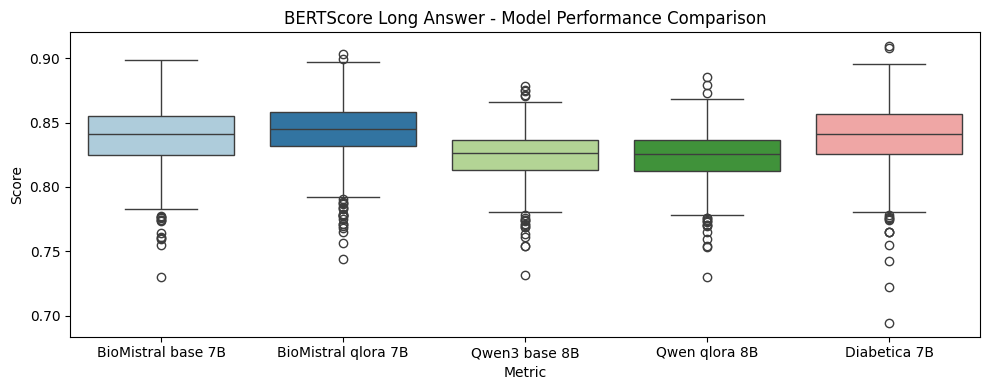

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_palette("colorblind")
plt.figure(figsize=(10, 4))
ax = sns.boxplot(data=results_df,  y='BERTScore-F1', x='index', palette='Paired')
plt.xlabel("Metric")
plt.ylabel("Score")
plt.title("BERTScore Long Answer - Model Performance Comparison")
plt.tight_layout()
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_palette("colorblind")
results_df = pd.DataFrame([biomistral_base_results, biomistral_qlora_results,
                           qwen_base_results, qwen_qlora_results, diabetica_results],
                          index=["biomistral base", "biomistral qlora", "qwen base", "qwen qlora",'diabetica']).T.reset_index()
results_melted = results_df.melt(id_vars='index', var_name='model', value_name='score')

plt.figure(figsize=(13, 6))
ax = sns.lineplot(data=results_melted, x='index', y='score', hue='model', palette='Paired')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')
plt.xlabel("Metric")
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.show()

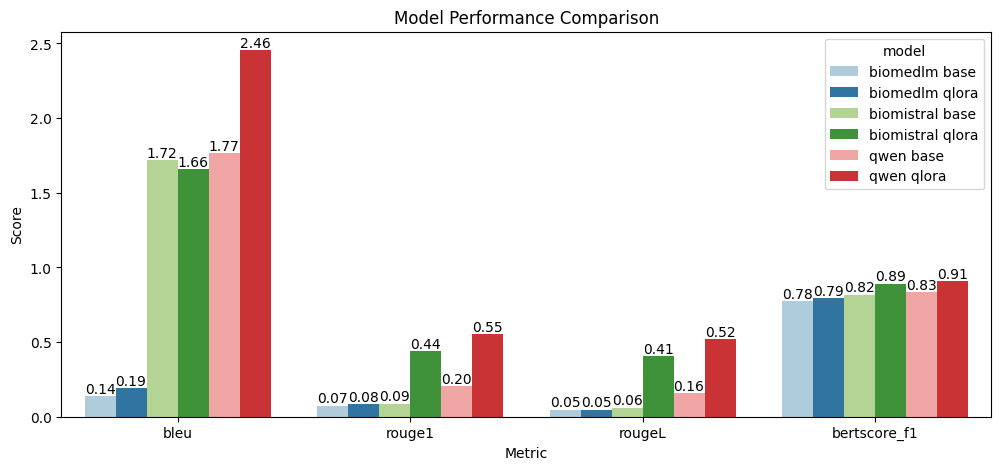

## MCQ

In [ ]:
mcq_df = final_df[final_df['type']=='MCQ']
mcq_df.head()

,instruction,question,answer,source,context,category,kind,options,long_answer,extract,...,biomistral_qlora_output,biomedlm_base_output,biomedlm_qlora_output,input_y,diabetica_output,biomistral_base_answer,biomistral_qlora_answer,qwen_base_answer,qwen_qlora_answer,diabetica_answer
0,You are a medical expert with advanced knowled...,Do severe but preventable foot burn injury in ...,A:yes,pubmedpqaa,['Due to the sensory loss in the lower extremi...,diabetes,None,"{'A': 'yes', 'B': 'no', 'C': 'maybe'}",Severe clinical consequences of foot burn inju...,None,...,Diabetes Virtual Doctor: The answer is A: yes....,"� boiling water baths and socks, especially th...",�If you don’t know?': \nExplanatory foot ulcer...,"\nYou are a helpful, respectful, honest, and s...",A yes\n\nDiabetic patients often suffer from p...,A: no. The development of ulcers on the feet c...,A: yes.,A: yes,A: yes,A yes
1,You are a medical expert with advanced knowled...,Do after 6years of intraperitoneal insulin adm...,A:yes,pubmedpqaa,['Low concentrations of insulin-like growth fa...,medication,None,"{'A': 'yes', 'B': 'no', 'C': 'maybe'}","After 6 years of treatment with CIPII, IGF-I c...",None,...,A: yes : Intraperitoneal insulin administrati...,"�boiled boiled, but the {D': '{[{[}, IAA}]/'.....",�istan: 'low-Normal Concentration of glucose l...,"\nYou are a helpful, respectful, honest, and s...",B: No\n\nThe data presented indicates that fol...,"B: No, because there is no significant change ...",A: yes : Intraperitoneal insulin administratio...,A: yes,A: yes,B: No
3,You are a medical expert with advanced knowled...,A 45 year old female patient comes to the clin...,C:CPT-I,mcqa,nan,diabetes,train,"{'A': '3-KetoacylCoA thiolase', 'B': 'HMG-CoA ...",The sulfonylurea drugs (glyburide and tolbuta...,None,...,You have been asked about the mechanism of act...,�meals were you paired with 'insulin sensitise...,�) Payne *et al*.\nThe purpose of this study':...,"\nYou are a helpful, respectful, honest, and s...",D: 3-hydroxyacyl-CoA dehydrogenase\n\nThe medi...,A: This drug works by inhibition of HMG CoA re...,You have been asked about the mechanism of act...,C:CPT-I stands for Carnitine Palmitoyltransfer...,C:CPT-I stands for Carnitine Palmitoyltransfer...,D: 3-hydroxyacyl-CoA dehydrogenase
5,You are a medical expert with advanced knowled...,The characteristic and common presentation of ...,C:Symmetrical sensory neuropathy,mcqa,nan,diabetes,train,"{'A': 'Amyotrophy', 'B': 'Mononeuropathy', 'C'...",Answer is C (Symmetrical sensory neuropathy): ...,None,...,You have been asked by your friend who has typ...,� you do not know which is the best example of...,� C': If a question is unclear why.\nAnswer\nA...,"\nYou are a helpful, respectful, honest, and s...",C: Symmetrical sensory neuropathy\n\nThis type...,The most common type of diabetic neuropathy is...,You have been asked by your friend who has typ...,C: Symmetrical sensory neuropathy,C: Symmetrical sensory neuropathy,C: Symmetrical sensory neuropathy
6,You are a medical expert with advanced knowled...,A 67-year-old male presents to the emergency d...,B:Increased cGMP,medqa,nan,medication,train,"{'A': 'Beta-adrenergic blockade', 'B': 'Increa...",None,None,...,A: Beta-adrenergic blockade: This patient's pr...,�Ringer's solution. Options 4:1 ratio of the f...,�C') were ranked 1st of the most important fac...,"\nYou are a helpful, respectful, honest, and s...",E: Left ventricular failure\n\nThe patient's p...,A: Beta-adrenergic blockade. This patient like...,A: Beta-adrenergic blockade: This patient's pr...,E: Left ventricular failure,E: Left ventricular failure,E: Left ventricular failure


In [ ]:
measure_df = final_df[final_df['type']=='MCQ']
diabetica_results = compute_mcq_metrics(measure_df['diabetica_answer'].str[0].tolist(),
                                    measure_df['answer'].str[0].tolist())
diabetica_results

{'accuracy': 0.7767475035663338}

In [ ]:
measure_df = final_df[final_df['type']=='MCQ']
qwen_base_results = compute_mcq_metrics(measure_df['qwen_base_answer'].str[0].tolist(),
                                    measure_df['answer'].str[0].tolist())
qwen_base_results

{'accuracy': 0.8059914407988588}

In [ ]:
measure_df = final_df[final_df['type']=='MCQ']
qwen_qlora_results = compute_mcq_metrics(measure_df['qwen_qlora_answer'].str[0].tolist(),
                                    measure_df['answer'].str[0].tolist())
qwen_qlora_results

{'accuracy': 0.8074179743223966}

In [ ]:
measure_df = final_df[(final_df['type'] =='MCQ')]
diabetica_results = compute_mcq_metrics(measure_df['diabetica_answer'].str[0].tolist(),
                                    measure_df['answer'].str[0].tolist())
diabetica_results

{'accuracy': 0.7767475035663338}

In [ ]:
measure_df = final_df[final_df['type'] =='MCQ']
biomistral_base_results = compute_mcq_metrics(measure_df['biomistral_base_answer'].str[0].tolist(),
                                    measure_df['answer'].str[0].tolist())
biomistral_base_results

{'accuracy': 0.42938659058487877}

In [ ]:
measure_df = final_df[final_df['type'] =='MCQ']
biomistral_qlora_results = compute_mcq_metrics(measure_df['biomistral_qlora_answer'].str[0].tolist(),
                                    measure_df['answer'].str[0].tolist())
biomistral_qlora_results

{'accuracy': 0.4044222539229672}

/tmp/ipython-input-1891873352.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=results_melted, y='score', x='model', palette='Paired')


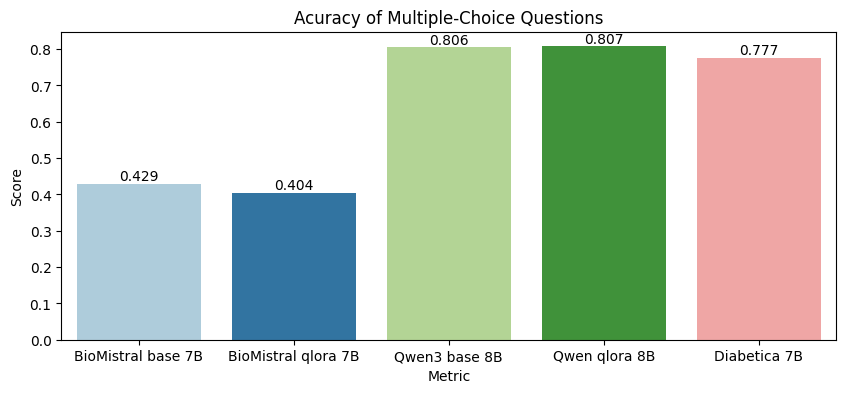

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_palette("colorblind")
results_df = pd.DataFrame([biomistral_base_results, biomistral_qlora_results,
                           qwen_base_results, qwen_qlora_results, diabetica_results],
                          index=["BioMistral base 7B", "BioMistral qlora 7B", "Qwen3 base 8B", "Qwen qlora 8B",'Diabetica 7B']).T.reset_index()
results_melted = results_df.melt(id_vars='index', var_name='model', value_name='score')

plt.figure(figsize=(10, 4))
ax = sns.barplot(data=results_melted, y='score', x='model', palette='Paired')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f')
plt.xlabel("Metric")
plt.ylabel("Score")
plt.title("Acuracy of Multiple-Choice Questions")
plt.show()

In [ ]:
final_df[final_df['question'].str.contains('asymptomatic')]

,instruction,question,answer,source,context,category,kind,options,long_answer,extract,...,biomistral_qlora_output,biomedlm_base_output,biomedlm_qlora_output,input_y,diabetica_output,biomistral_base_answer,biomistral_qlora_answer,qwen_base_answer,qwen_qlora_answer,diabetica_answer
113,You are a medical expert with advanced knowled...,Is albumin excretion rate affected by asymptom...,B:no,pubmedpqaa,['The aim of the study was to evaluate whether...,diabetes,None,"{'A': 'yes', 'B': 'no', 'C': 'maybe'}",Asymptomatic UTI does not increase AER in type...,None,...,Albumin excretion rate does not seem to be inf...,� should read:\n>\n> The study aimed at evalua...,�Paired samples of 20 mg/day or more increased...,"\nYou are a helpful, respectful, honest, and s...",B: No\n\nBased on the results of the study des...,B: no. Albumin excretion rate does not change ...,Albumin excretion rate does not seem to be inf...,B: no,B: no,B: No
372,You are a medical expert with advanced knowled...,Is sudoscan an effective screening method for ...,A:yes,pubmedpqaa,['The aim of the present study was to use the ...,diabetes,None,"{'A': 'yes', 'B': 'no', 'C': 'maybe'}",Sudoscan might be a promising tool to screen a...,None,...,A: yes : The findings suggest that Sudoscan ca...,"� Boolean{7}, ![](IJEM-12-28550_Figd_HTML.gif)...",�') 'It depends on whether you are a useful to...,"\nYou are a helpful, respectful, honest, and s...",A yes\n\nSudoscan appears to be an effective s...,A: yes. The study by Zhang et al. demonstrated...,A: yes : The findings suggest that Sudoscan ca...,A: yes,A: yes,A yes
1044,You are a medical expert with advanced knowled...,A 3-year-old boy presents with excessive growt...,The clinical presentation described is consist...,medical-o1-reasoning-SFT,nan,diabetes,None,None,None,None,...,The child's clinical presentation suggests a r...,�Eggs can't move my child's family history? Ye...,� I am not a substitute for referral to the pa...,"\nYou are a helpful, respectful, honest, and s...",The child's symptoms suggest a diagnosis consi...,NaN,NaN,NaN,NaN,NaN
1592,You are a medical expert with advanced knowled...,Does the BNP assay identify mild left ventricu...,B:no,pubmedpqaa,['We examined the usefulness of BNP for screen...,diabetes,None,"{'A': 'yes', 'B': 'no', 'C': 'maybe'}",Our data confirm alarmingly high prevalence of...,None,...,B: no\nExplanation: The results suggest that t...,"�, without any kind of mitral regurgitation an...","�' 'No', 'myocardial infarction was a useful m...","\nYou are a helpful, respectful, honest, and s...",B: No\n\nThe study did not find significant di...,B: no The study did not find significant diffe...,B: no\nExplanation: The results suggest that t...,B: No,B: No,B: No


In [ ]:
selected_df = final_df.iloc[0]
print(f"Context: {selected_df['context']}")
print(f"Question: {selected_df['question']}")
print(f"Options: {selected_df['options']}")
print(f"Answer: {selected_df['answer']}")
print(f"Long-answer/Explanation: {selected_df['long_answer']}")
print(f"BioMedLM base generated answer: {selected_df['biomedlm_base_output']}")
print(f"BioMedLM QLoRA generated answer: {selected_df['biomedlm_qlora_output']}")

Context: ['Due to the sensory loss in the lower extremities, accidental foot injuries may develop in diabetic patients with distal sensorimotor polyneuropathy. Unusual etiologies of foot injury may be of interest.', 'Patient 1, a 51-year-old type 2 diabetic patient, was observed with a burn injury of the digits I-V of the right foot due to an unperceived thermal injury while working at a house construction site and wearing shoes. Patient 2, a 66-year-old type 2 diabetic patient, tried to treat a small dermal lesion caused by improper footwear by using a hot paraffin footbath, but during this unusual self-treatment a painless and unperceived burn injury developed. Bed rest, local disinfection, antibiotics, and minimal surgical intervention (partial amputation, debridement) were applied. After long healing periods, both patients recovered with acceptable residual findings.']
Question: Do severe but preventable foot burn injury in diabetic patients with peripheral neuropathy?
Options: {'A

In [ ]:
#print question and varying answers
selected_df = final_df.iloc[0]
print(f"Context: {selected_df['context']}")
print(f"Question: {selected_df['question']}")
print(f"Options: {selected_df['options']}")
print(f"Long-answer/Explanation: {selected_df['long_answer']}")
print(f"BioMistral base generated answer: {selected_df['biomistral_base_output']}")
print(f"Qwen3 base generated answer: {selected_df['qwen_base_output']}")
print(f"BioMistral generated answer: {selected_df['biomistral_qlora_output']}")
print(f"Qwen3 generated answer: {selected_df['qwen_qlora_output']}")
print(f"Diabetica generated answer: {selected_df['diabetica_output']}")

Context: ['Due to the sensory loss in the lower extremities, accidental foot injuries may develop in diabetic patients with distal sensorimotor polyneuropathy. Unusual etiologies of foot injury may be of interest.', 'Patient 1, a 51-year-old type 2 diabetic patient, was observed with a burn injury of the digits I-V of the right foot due to an unperceived thermal injury while working at a house construction site and wearing shoes. Patient 2, a 66-year-old type 2 diabetic patient, tried to treat a small dermal lesion caused by improper footwear by using a hot paraffin footbath, but during this unusual self-treatment a painless and unperceived burn injury developed. Bed rest, local disinfection, antibiotics, and minimal surgical intervention (partial amputation, debridement) were applied. After long healing periods, both patients recovered with acceptable residual findings.']
Question: Do severe but preventable foot burn injury in diabetic patients with peripheral neuropathy?
Options: {'A

In [ ]:
selected_df.index

Index([1968], dtype='int64')